# Airline Review Analysis - Notebook 10: Summarising What Passengers Say (LexRank)

An airline can have thousands of complaints about one topic, and nobody can read them all. A **summary** shows the main points in a few sentences.

There are two kinds of automatic summaries:
- **Abstractive**: writes new sentences (this needs a generative model).
- **Extractive**: picks the most important existing sentences. This is the method I use.

Syllabus topics used here (Unit 3): text summarization, **LexRank**, and summarization evaluation.

Input: `data/aspect_segments.csv` (from Notebook 6), `data/reviews_preprocessed.csv`
Output: `data/lexrank_summaries.csv` (used by the dashboard)

## 1. How LexRank works

LexRank treats the sentences as a **graph**:

1. Every sentence becomes a TF-IDF vector (as in Notebook 4).
2. The similarity between every two sentences is measured with the **cosine similarity** (1 means the same words, 0 means no words in common).
3. Two sentences are connected if their similarity is above a threshold.
4. A sentence is important if it is connected to many other sentences that are important themselves. This is the same idea as Google's PageRank: it is calculated by repeating the calculation until the scores stop changing (power iteration).
5. The sentences with the highest scores are the summary.

In simple words: a sentence that says what many other passengers also say is a good summary of all of them.

## 2. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 200)

df = pd.read_csv("data/reviews_preprocessed.csv", usecols=["airline"])
pieces = pd.read_csv("data/aspect_segments.csv")
pieces["airline"] = df.loc[pieces["review_id"], "airline"].values

pieces["n_words"] = pieces["text"].str.split().str.len()
pieces = pieces[(pieces["n_words"] >= 8) & (pieces["n_words"] <= 35)]      # not too short, not too long
print(len(pieces), "pieces of text")

304617 pieces of text


## 3. LexRank from scratch

In [2]:
def lexrank_scores(sentences, threshold=0.1, damping=0.85, iterations=50):
    vectors = TfidfVectorizer(stop_words="english").fit_transform(sentences)
    similarity = cosine_similarity(vectors)
    np.fill_diagonal(similarity, 0)

    connected = (similarity > threshold).astype(float)          # 1 if two sentences are similar enough
    n = len(sentences)
    row_sums = connected.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1                                 # sentences with no neighbours
    transition = connected / row_sums                           # chance of moving from one sentence to another

    scores = np.ones(n) / n
    for _ in range(iterations):
        scores = (1 - damping) / n + damping * transition.T @ scores
    return scores, similarity


def summarise_sentences(sentences, n=3, max_overlap=0.5):
    scores, similarity = lexrank_scores(sentences)
    chosen = []
    for i in np.argsort(-scores):                              # best sentence first
        # skip a sentence that is almost the same as one that is already chosen
        if all(similarity[i, j] < max_overlap for j in chosen):
            chosen.append(i)
        if len(chosen) == n:
            break
    return [sentences[i] for i in chosen]

A small test with five sentences about delays, where two are about the same thing:

In [3]:
test = ["The flight was delayed for five hours",
        "Our flight was delayed by five hours and nobody told us anything",
        "The food was good and the crew was friendly",
        "Nobody told us anything about the delay at the gate",
        "I like to fly in the morning"]
scores, _ = lexrank_scores(test)
for s, sc in sorted(zip(test, scores), key=lambda x: -x[1]):
    print(round(sc, 3), "|", s)

0.292 | Our flight was delayed by five hours and nobody told us anything
0.154 | The flight was delayed for five hours
0.154 | Nobody told us anything about the delay at the gate
0.03 | The food was good and the crew was friendly
0.03 | I like to fly in the morning


The sentences about the delay and about the lack of information support each other, so they get the highest scores. The sentences about food and about preferences are not connected to the others and get the lowest scores.

## 4. Summarising one airline and one topic

I take all negative pieces of text (score below 0.35, as in Notebook 6) about one topic of one airline, and show the 3 most central ones.

In [4]:
def get_sentences(airline, topic, kind="negative", max_sentences=600):
    subset = pieces[(pieces["airline"] == airline) & (pieces["topic"] == topic)]
    if kind == "negative":
        subset = subset[subset["learned"] < 0.35]
    else:
        subset = subset[subset["learned"] >= 0.65]
    subset = subset.drop_duplicates(subset="text")
    if len(subset) > max_sentences:
        subset = subset.sample(max_sentences, random_state=1)       # keeps the calculation fast
    return subset["text"].tolist()


def summary(airline, topic, kind="negative", n=3):
    sentences = get_sentences(airline, topic, kind)
    print(airline, "-", topic, "-", kind, "(" + str(len(sentences)) + " sentences)")
    if len(sentences) < 30:
        print("  not enough sentences")
        return
    for s in summarise_sentences(sentences, n):
        print("  -", s)
    print()

summary("American Airlines", "delay")
summary("American Airlines", "baggage")
summary("Emirates", "seat")
summary("Emirates", "cabin_crew", kind="positive")

American Airlines - delay - negative (600 sentences)
  - My flight was delayed for over an hour
  - Every flight is hours delayed and yet you always seem to miss your connecting flight
  - my flight to Dallas was delayed by six hours

American Airlines - baggage - negative (600 sentences)
  - I was told to give my carry-on bag over to them
  - They also would not give us our luggage
  - They made us check our carry on bags because they said they were full

Emirates - seat - negative (561 sentences)
  - Then get out of your seat and go and find them
  - I did ask for a change of seat at the gate and in flight and every time I was told there were no empty seats
  - The seats are uncomfortable for such a long flight

Emirates - cabin_crew - positive (525 sentences)
  - The cabin crew on this flight were friendly and attentive
  - Great service from the cabin crew, who were attentive
  - The cabin was clean, cabin crew professional and friendly



**Observations**

The summaries show the typical points. For American Airlines delays they mention flights delayed by hours and missed connections, and for baggage they mention being made to check carry-on bags and not getting luggage back. For Emirates seats they mention uncomfortable seats on long flights and trouble getting a seat change, and the positive summary for the cabin crew says the crew are friendly, attentive and professional.

LexRank chooses sentences that are similar to many other sentences, so the result is typical but not always detailed. A piece of text can also match a topic only by chance, for example "Then get out of your seat and go and find them" in the first Emirates seat summary.

## 5. Evaluating the summaries

Summaries are usually evaluated with **ROUGE**, which compares the words of the summary with a summary written by a person. I do not have human-written summaries (and I do not want to write them by hand), so I use an automatic check of how **representative** the summary is: for every selected sentence, the average cosine similarity to all the other sentences about that topic. A higher value means the selected sentences are more typical of what passengers say.

I compare LexRank with three simple alternatives on 30 airline and topic combinations:
- 3 random sentences (average of 20 random draws)
- the 3 longest sentences
- the first 3 sentences

In [5]:
combos = []
for airline in pieces["airline"].value_counts().head(10).index:
    for topic in ["delay", "baggage", "ground_staff"]:
        combos.append((airline, topic))

rng = np.random.default_rng(0)
rows = []
for airline, topic in combos:
    sentences = get_sentences(airline, topic)
    if len(sentences) < 50:
        continue
    scores, similarity = lexrank_scores(sentences)
    n = len(sentences)

    def representative(indices):
        # average similarity between the chosen sentences and all the other sentences
        return np.mean([similarity[i].sum() / (n - 1) for i in indices])

    lexrank_choice = [sentences.index(s) for s in summarise_sentences(sentences, 3)]
    longest = np.argsort([-len(s) for s in sentences])[:3]
    random_scores = [representative(rng.choice(n, 3, replace=False)) for _ in range(20)]

    rows.append({"airline": airline, "topic": topic, "sentences": n,
                 "LexRank": representative(lexrank_choice),
                 "random": np.mean(random_scores),
                 "longest": representative(longest),
                 "first": representative([0, 1, 2])})

evaluation = pd.DataFrame(rows)
print(len(evaluation), "combinations")
evaluation[["LexRank", "random", "longest", "first"]].mean().round(4)

30 combinations


LexRank    0.0713
random     0.0275
longest    0.0239
first      0.0253
dtype: float64

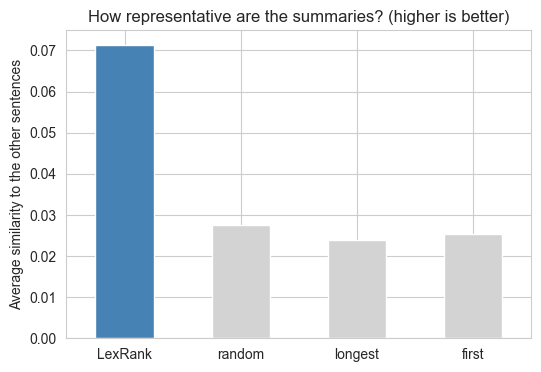

LexRank is better than all three alternatives in 100 % of the combinations


In [6]:
evaluation[["LexRank", "random", "longest", "first"]].mean().plot(kind="bar", color=["steelblue", "lightgrey", "lightgrey", "lightgrey"], figsize=(6, 4))
plt.title("How representative are the summaries? (higher is better)")
plt.ylabel("Average similarity to the other sentences")
plt.xticks(rotation=0)
plt.show()

wins = (evaluation["LexRank"] > evaluation[["random", "longest", "first"]].max(axis=1)).mean()
print("LexRank is better than all three alternatives in", round(wins * 100), "% of the combinations")

**Observations**

LexRank is clearly more representative than the alternatives: 0.071 against about 0.025 for random, longest and first sentences, and it is better in all 30 combinations. This is expected, because LexRank selects sentences by how similar they are to the others, which is also what this check measures. So the check shows that the algorithm works as intended, but it does not prove that a person finds the summaries useful. For that I would need summaries written by people to calculate ROUGE.

## 6. Summaries for all airlines (for the dashboard)

For every airline with at least 300 reviews, and every topic with at least 30 negative sentences, I save the top 3 sentences. The same is done for positive sentences. This takes a few minutes.

In [7]:
big_airlines = df["airline"].value_counts()
big_airlines = big_airlines[big_airlines >= 300].index

rows = []
for airline in big_airlines:
    for topic in pieces["topic"].unique():
        for kind in ["negative", "positive"]:
            sentences = get_sentences(airline, topic, kind)
            if len(sentences) < 30:
                continue
            for rank, sentence in enumerate(summarise_sentences(sentences, 3), start=1):
                rows.append({"airline": airline, "topic": topic, "kind": kind,
                             "sentences": len(sentences), "rank": rank, "summary_sentence": sentence})

lexrank_summaries = pd.DataFrame(rows)
lexrank_summaries.to_csv("data/lexrank_summaries.csv", index=False)
print("saved", len(lexrank_summaries), "summary sentences for",
      lexrank_summaries[["airline", "topic", "kind"]].drop_duplicates().shape[0], "airline-topic-kind combinations")

saved 2976 summary sentences for 992 airline-topic-kind combinations


## Summary

- LexRank was built from scratch: TF-IDF vectors, cosine similarity between sentences, a graph of similar sentences, and a PageRank style calculation that gives the most central sentences the highest scores. A small overlap rule avoids choosing two almost identical sentences.
- It was used to summarise what passengers say about a topic of an airline (negative and positive).
- Without human-written summaries ROUGE cannot be used, so a representativeness check was used instead. LexRank beat random, longest and first sentences in all 30 combinations.
- Summaries for 992 airline, topic and sentiment combinations (2,976 sentences) are saved in `data/lexrank_summaries.csv` for the dashboard.

Limits: the summary sentences are typical but short, and topic matching by keywords can pick a sentence by chance.

Next: the dashboard (`app.py`).